# 2 · Perception meets a program: MNIST addition

Each example shows two $N$-digit numbers as $2N$ handwritten MNIST images, and tells us only their **sum**. We want a network that reads digits, without ever seeing a digit label.

Notebook 1 introduced worlds, potentials, inference and learning. This one adds:

1. **inputs attached to constants**: every image is a constant of the language, and the model is conditional, $p(y \mid x)$;
2. **categorical variables**: an image shows exactly one digit;
3. **background knowledge** (built-ins) and a **symbolic program** written as hard rules;
4. a **neural predicate**: a CNN scores the digit of each image;
5. **exact belief propagation**, because the program has a tree-shaped factor graph;
6. **learning from partially observed worlds**: digits and carries stay latent, and the loss is $-\log p(\text{sum} \mid \text{images})$.

In [1]:
import os
from collections import Counter

import certifi
import matplotlib.pyplot as plt
import torch
import torchvision
from torch.utils.data import DataLoader, default_collate

import nmln

os.environ.setdefault("SSL_CERT_FILE", certifi.where())  # lets the MNIST download verify certificates everywhere
torch.manual_seed(0)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
DATA, MODEL, EXACT, NEURAL = "#9aa5b1", "#2563eb", "#dc2626", "#16a34a"

transform = torchvision.transforms.Compose(
    [torchvision.transforms.ToTensor(), torchvision.transforms.Normalize((0.1307,), (0.3081,))]
)
train_mnist = torchvision.datasets.MNIST("data", train=True, download=True, transform=transform)
test_mnist = torchvision.datasets.MNIST("data", train=False, download=True, transform=transform)
print(len(train_mnist), "training images,", len(test_mnist), "test images")

60000 training images, 10000 test images


## 1. The task

With $N = 2$, an example is four images: $a_1 a_0$ writes the first number and $b_1 b_0$ the second (index 0 is the least significant digit). The data only tell us the sum, e.g. $47 + 85 = 132$.

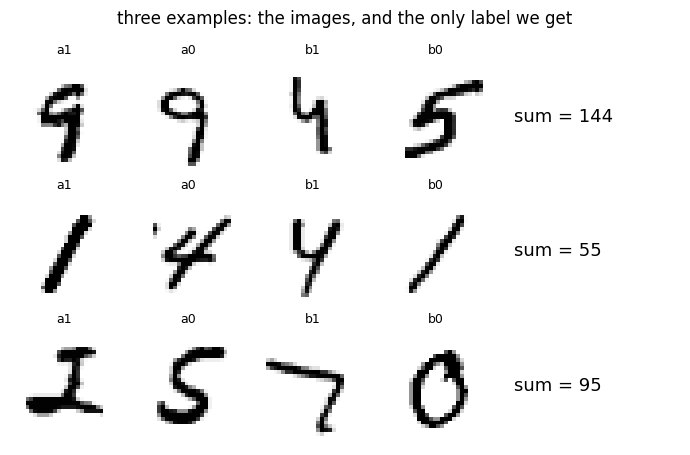

In [2]:
N = 2


def to_number(digits):
    # digits [..., N], least significant first
    return (digits * 10 ** torch.arange(digits.shape[-1])).sum(-1)


def show(images, digits, total, title=None, ax_row=None):
    n = len(images) // 2
    order = list(range(n - 1, -1, -1)) + list(range(2 * n - 1, n - 1, -1))  # most significant first
    axes = ax_row if ax_row is not None else plt.subplots(1, 2 * n, figsize=(1.4 * 2 * n, 1.6))[1]
    for ax, i in zip(axes, order):
        ax.imshow(images[i, 0], cmap="Greys")
        ax.set_title(("a" if i < n else "b") + str(i % n), fontsize=9)
        ax.axis("off")
    return axes


raw = torchvision.datasets.MNIST("data", train=True)
fig, axes = plt.subplots(3, 2 * N + 1, figsize=(7, 4.6), gridspec_kw={"width_ratios": [1] * 2 * N + [1.6]})
for row in range(3):
    idx = torch.randint(len(train_mnist), (2 * N,))
    images = torch.stack([train_mnist[i][0] for i in idx])
    labels = torch.tensor([raw.targets[i] for i in idx])
    show(images, labels, None, ax_row=axes[row, :2 * N])
    total = int(to_number(labels[:N]) + to_number(labels[N:]))
    axes[row, -1].text(0.05, 0.5, f"sum = {total}", fontsize=13, va="center")
    axes[row, -1].axis("off")
plt.suptitle("three examples: the images, and the only label we get")
plt.tight_layout()
plt.show()

## 2. A conditional relational language

**Constants carry inputs.** The images are constants of a domain declared with `input_shape`: in every example, each of $a_0, a_1, b_0, b_1$ comes with a $1 \times 28 \times 28$ image, given in the batch as `x["images"]`. The world $y$ describes the individuals; the inputs $x$ are always observed, and the model is $p(y \mid x)$.

**Predicates.** `digit(Image, Value)`: the digit an image shows; `res(Pos, Value)`: the digit of the sum at each position; `carry(Pos, Bit)`: the carry into each position (the sum has $N + 1$ digits).

**Categorical variables.** An image shows exactly one digit, so the ten atoms `digit(a0, 0)`, …, `digit(a0, 9)` form one variable, declared with `Categorical("digit", over="value")`. The possible worlds are the combinations of the variables' values.

In [3]:
def build_language(n_digits):
    images = nmln.Domain("images", [f"a{i}" for i in range(n_digits)] + [f"b{i}" for i in range(n_digits)],
                         input_shape=(1, 28, 28))
    pos = nmln.Domain("pos", list(range(n_digits + 1)))
    value = nmln.Domain("value", list(range(10)))
    bit = nmln.Domain("bit", [0, 1])
    return nmln.Ontology(
        [images, pos, value, bit],
        [nmln.Predicate("digit", [images, value]), nmln.Predicate("res", [pos, value]), nmln.Predicate("carry", [pos, bit])],
        builtins=[
            nmln.Builtin("first", [images, pos], facts=[(f"a{i}", i) for i in range(n_digits)]),
            nmln.Builtin("second", [images, pos], facts=[(f"b{i}", i) for i in range(n_digits)]),
            nmln.Builtin("next", [pos, pos], fn=lambda i, j: j == i + 1),
            nmln.Builtin("last", [pos], fn=lambda i: i == n_digits),
            nmln.Builtin("add", [value, value, bit, value, bit], fn=lambda a, b, c, s, d: a + b + c == s + 10 * d),
            nmln.Builtin("same", [bit, value], fn=lambda c, v: c == v),
        ],
        variables=[nmln.Categorical("digit", over="value"), nmln.Categorical("res", over="value"),
                   nmln.Categorical("carry", over="bit")],
    )


ontology = build_language(N)
print(ontology)
print()
print("the variables:", [ontology.variables.name(v) for v in range(len(ontology.variables))])

Ontology: 76 ground atoms, 10 variables
  domains:    images (4), pos (3), value (10), bit (2)
  predicates: digit(images, value), res(pos, value), carry(pos, bit)
  built-ins:  first/2, second/2, next/2, last/1, add/5, same/2
  variables:  Categorical(['digit'], over='value'), Categorical(['res'], over='value'), Categorical(['carry'], over='bit')

the variables: ['digit(a0,·)', 'digit(a1,·)', 'digit(b0,·)', 'digit(b1,·)', 'res(0,·)', 'res(1,·)', 'res(2,·)', 'carry(0,·)', 'carry(1,·)', 'carry(2,·)']


A complete world for the example $47 + 85 = 132$ assigns a digit to every image, a carry to every position, and a digit to every position of the sum. The data observe only the sum: those are the **evidence**, everything else is **latent**.

In [4]:
def complete_world(ontology, digits, n_digits):
    # the full world of an addition: digits, carries and the digits of the sum
    a, b = digits[:n_digits].tolist(), digits[n_digits:].tolist()
    atoms, carry = [], 0
    for i in range(n_digits):
        atoms += [f"digit(a{i},{a[i]})", f"digit(b{i},{b[i]})", f"carry({i},{carry})"]
        total = a[i] + b[i] + carry
        atoms.append(f"res({i},{total % 10})")
        carry = total // 10
    atoms += [f"carry({n_digits},{carry})", f"res({n_digits},{carry})"]
    return ontology.world(atoms)


world = complete_world(ontology, torch.tensor([7, 4, 5, 8]), N)  # a = 47, b = 85 (least significant digit first)
evidence = ontology.observe(world, ["res"])
print("complete world:", ontology.true_atoms(world))
print("observed atoms:", [ontology.atom(i) for i in evidence.observed.nonzero().flatten() if world[i]],
      f"+ the other {int(evidence.observed.sum()) - 3} res atoms, observed false")
print("latent atoms:  ", int((~evidence.observed).sum()), "(every digit and carry atom)")

complete world: ['digit(a0,7)', 'digit(a1,4)', 'digit(b0,5)', 'digit(b1,8)', 'res(0,2)', 'res(1,3)', 'res(2,1)', 'carry(0,0)', 'carry(1,1)', 'carry(2,1)']
observed atoms: ['res(0,2)', 'res(1,3)', 'res(2,1)'] + the other 27 res atoms, observed false
latent atoms:   46 (every digit and carry atom)


## 3. Background knowledge: built-ins

Some predicates have the same meaning in every possible world: the layout of an example (`first(a0, 0)`: image $a_0$ is the first number's digit at position 0), the order of positions (`next`), and arithmetic (`add(A, B, C, S, D)` means $A + B + C = S + 10D$). These are **built-ins**: background knowledge, not random variables. They are not part of the world $y$, the data never provide them, and the samplers never see them.

In [5]:
add = ontology.builtins["add"].table()  # a bool table over (value, value, bit, value, bit)
print("add(7, 5, 0, 2, 1):", add[7, 5, 0, 2, 1], "  (7 + 5 + 0 = 2 + 10·1)")
print("add(7, 5, 0, 3, 1):", add[7, 5, 0, 3, 1])
print(f"add is true for {add.sum()} of its {add.size} tuples: one (S, D) for every (A, B, C)")
print("first:", ontology.builtins["first"].facts, " second:", ontology.builtins["second"].facts)

add(7, 5, 0, 2, 1): True   (7 + 5 + 0 = 2 + 10·1)
add(7, 5, 0, 3, 1): False
add is true for 200 of its 4000 tuples: one (S, D) for every (A, B, C)
first: [('a0', 0), ('a1', 1)]  second: [('b0', 0), ('b1', 1)]


## 4. The program, as hard rules

Addition in the **carry representation**: one rule per column says that the two digits and the incoming carry give the result digit and the outgoing carry. Two more rules fix the first carry to 0 and make the last carry the leading digit of the sum.

The rules are **hard**: every false grounding costs a huge penalty, so worlds that break them have (numerically) zero probability. `nmln.normal_form` shows each rule as it is evaluated, without the implication and with negations on single atoms.

In [6]:
PROGRAM = [
    # column I: the digits of the two numbers and the incoming carry give the result digit and the outgoing carry
    """first(X,I) and second(Y,I) and next(I,J)
       and digit(X,A) and digit(Y,B) and carry(I,C) and add(A,B,C,S,D)
       -> res(I,S) and carry(J,D)""",
    # nothing is carried into the first column
    "carry(0,0)",
    # the last carry is the leading digit of the sum
    "last(I) and carry(I,C) and same(C,V) -> res(I,V)",
]
program = [nmln.SymbolicPotential(ontology, rule, hard=True) for rule in PROGRAM]

print("normal form of the column rule:\n ", nmln.normal_form(PROGRAM[0]))
print()
for potential in program:
    print(f"{potential.num_groundings:5d} groundings of {potential.rule[:60]}")
print("\ntwo of them:\n ", "\n  ".join(program[0].groundings(2)))

normal form of the column rule:
  not first(X,I) or not second(Y,I) or not next(I,J) or not digit(X,A) or not digit(Y,B) or not carry(I,C) or not add(A,B,C,S,D) or (res(I,S) and carry(J,D))

  400 groundings of first(X,I) and second(Y,I) and next(I,J) and digit(X,A) and 
    1 groundings of carry(0,0)
    2 groundings of last(I) and carry(I,C) and same(C,V) -> res(I,V)

two of them:
  first(a0,0) and second(b0,0) and next(0,1) and digit(a0,0) and digit(b0,0) and carry(0,0) and add(0,0,0,0,0) -> res(0,0) and carry(1,0)
  first(a0,0) and second(b0,0) and next(0,1) and digit(a0,0) and digit(b0,0) and carry(0,1) and add(0,0,1,1,0) -> res(0,1) and carry(1,0)


The column rule has 9 variables. Their bindings number $(2N)^2 (N+1)^2 \cdot 10 \cdot 10 \cdot 2 \cdot 10 \cdot 2$, but most of them make a built-in in the body false, so the implication is true in every world and the grounding is dropped when the potential is built. What survives is one grounding per column and per $(A, B, C)$: $N \cdot 200$.

In [7]:
bindings = (2 * N) ** 2 * (N + 1) ** 2 * 10 * 10 * 2 * 10 * 2
print(f"{bindings:,} bindings  ->  {program[0].num_groundings} groundings kept")

576,000 bindings  ->  400 groundings kept


## 5. The neural predicate

A **unary neural potential** connects perception to the world: a CNN reads the image of each constant $c$ and scores the ten atoms `digit(c, v)`,

$$\phi(y, x) = \sum_{c} \sum_{v} y[\texttt{digit}(c, v)] \cdot f_\theta(x_c)[v].$$

On a categorical variable this is a softmax classifier per image: $f_\theta(x_c)$ are the logits. The same network is shared by all images.

logits: (1, 4, 10) = [examples, images, digits]


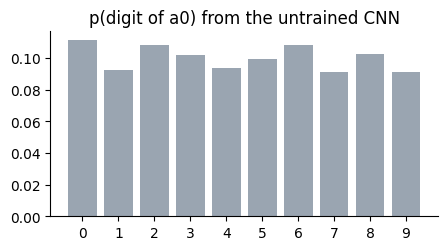

In [8]:
class DigitClassifier(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Conv2d(1, 16, 5), torch.nn.MaxPool2d(2), torch.nn.ReLU(),
            torch.nn.Conv2d(16, 32, 5), torch.nn.MaxPool2d(2), torch.nn.ReLU(),
            torch.nn.Flatten(), torch.nn.Linear(32 * 4 * 4, 128), torch.nn.ReLU(), torch.nn.Linear(128, 10),
        )

    def forward(self, images):
        return self.net(images)


cnn = DigitClassifier()
neural = nmln.UnaryNeuralPotential(ontology, "digit", cnn)
x = {"images": torch.stack([train_mnist[i][0] for i in range(2 * N)]).unsqueeze(0)}  # one example: [B=1, 2N, 1, 28, 28]
with torch.no_grad():
    logits = neural.logits(x)
print("logits:", tuple(logits.shape), "= [examples, images, digits]")
plt.figure(figsize=(5, 2.4))
plt.bar(range(10), logits[0, 0].softmax(-1), color=DATA)
plt.xticks(range(10))
plt.title("p(digit of a0) from the untrained CNN")
plt.show()

## 6. The model and its factor graph

The NMLN puts the neural predicate and the program on the same world:

$$p(y \mid x) \propto \exp\Big(\phi_{\text{CNN}}(y, x) + \sum_{\text{rules}} \beta_{\text{hard}} \cdot \phi_{\text{rule}}(y)\Big).$$

**Belief propagation** turns the potentials into a factor graph: the CNN gives one factor per image, and each column grounding reads five variables, so the program gives one factor per column. The columns are linked only through the carries: the factor graph is a **tree**, so BP is exact, and its cost grows linearly with $N$.

In [9]:
model = nmln.NMLN(ontology, [neural, *program])
bp = nmln.BeliefPropagation(model)
print(bp.describe())

10 variables, 3 factors over 2 or more variables; a tree: BP is exact
  factor 0: digit(a0,·), digit(b0,·), res(0,·), carry(0,·), carry(1,·)
  factor 1: digit(a1,·), digit(b1,·), res(1,·), carry(1,·), carry(2,·)
  factor 2: res(2,·), carry(2,·)


The representation of the program decides whether this is tractable. Written in the carry representation, a column factor has $10 \cdot 10 \cdot 2 \cdot 10 \cdot 2 = 4000$ entries. Written as one rule over whole numbers, the factor would range over all $10^{2N}$ combinations of the digits (times the sum's digits):

In [10]:
for n in (1, 2, 4, 15):
    print(f"N = {n:2d}: carry representation {n} × 4000 = {n * 4000:>7,} entries   |   whole numbers: 10^{2 * n} digit combinations")

N =  1: carry representation 1 × 4000 =   4,000 entries   |   whole numbers: 10^2 digit combinations
N =  2: carry representation 2 × 4000 =   8,000 entries   |   whole numbers: 10^4 digit combinations
N =  4: carry representation 4 × 4000 =  16,000 entries   |   whole numbers: 10^8 digit combinations
N = 15: carry representation 15 × 4000 =  60,000 entries   |   whole numbers: 10^30 digit combinations


**Is BP really exact?** On 1-digit addition we can also enumerate all $10^4 \cdot 4 = 40\,000$ worlds with `Exact`, and compare $\log p(\text{sum} \mid \text{images})$:

In [11]:
class MNISTAddition(torch.utils.data.Dataset):
    # each example: 2N images (a0..a{N-1}, b0..b{N-1}) and the world in which only the sum is observed
    def __init__(self, mnist, ontology, n_digits, seed=0):
        order = torch.randperm(len(mnist), generator=torch.Generator().manual_seed(seed))
        self.groups = order[:len(order) // (2 * n_digits) * (2 * n_digits)].view(-1, 2 * n_digits)
        self.mnist, self.ontology, self.n = mnist, ontology, n_digits

    def __len__(self):
        return len(self.groups)

    def __getitem__(self, i):
        images, labels = zip(*(self.mnist[j] for j in self.groups[i].tolist()))
        labels = torch.tensor(labels)
        total = int(to_number(labels[:self.n]) + to_number(labels[self.n:]))
        world = self.ontology.world(f"res({k},{total // 10 ** k % 10})" for k in range(self.n + 1))
        return {"x": {"images": torch.stack(images)}, "y": world, "observed": self.ontology.mask(["res"]),
                "digits": labels, "sum": total}


one_digit = build_language(1)
small = nmln.NMLN(one_digit, [nmln.UnaryNeuralPotential(one_digit, "digit", DigitClassifier()),
                              *[nmln.SymbolicPotential(one_digit, rule, hard=True) for rule in PROGRAM]])
batch = default_collate([MNISTAddition(train_mnist, one_digit, 1)[i] for i in range(4)])
sums = nmln.Evidence(batch["y"], batch["observed"])
print("BP:   ", nmln.BeliefPropagation(small).log_probability(sums, x=batch["x"]).detach().numpy().round(4))
print("Exact:", nmln.Exact(small).log_probability(sums, x=batch["x"]).detach().numpy().round(4))

BP:    [-2.6656 -2.3085 -2.4858 -3.1413]


Exact: [-2.6656 -2.3085 -2.4858 -3.1413]


## 7. Learning from sums only

The digits and carries are latent, so we maximize the probability of what we observe, the sum:

$$-\log p(\text{sum} \mid x) = \log Z(x) - \log Z(x, \text{sum}),$$

where $Z(x, \text{sum})$ sums over the worlds that agree with the observed sum. BP computes both exactly, and autograd carries the gradient through the program to the CNN. It is the same "data minus model" gradient as in notebook 1, with the data side now an expectation over the latent digits given the sum.

One pass over the training images (15 000 sums), written as a loop; every 100 steps we read 500 test examples with the model, from the images alone.

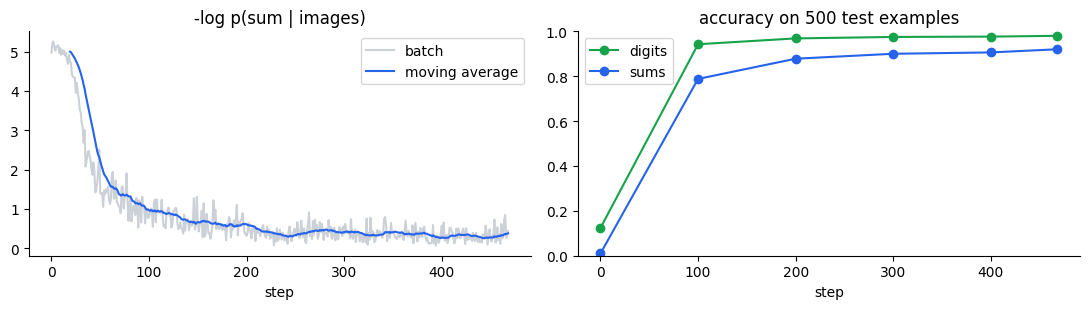

In [12]:
train = MNISTAddition(train_mnist, ontology, N, seed=0)
test = MNISTAddition(test_mnist, ontology, N, seed=1)
digit_index, res_index = ontology.indices("digit"), ontology.indices("res")


def read(batch):
    # MAP world given the images only: (predicted digits, predicted sums)
    world = bp.map(x=batch["x"])
    return world[:, digit_index].argmax(-1), to_number(world[:, res_index].argmax(-1))


probe = default_collate([test[i] for i in range(500)])
learner = nmln.MaximumLikelihood(bp)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
log = {"step": [], "loss": [], "eval_step": [], "digits": [], "sums": []}
for step, batch in enumerate(DataLoader(train, batch_size=32, shuffle=True)):
    loss = learner.loss(batch)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    log["step"].append(step)
    log["loss"].append(loss.item())
    if step % 100 == 0 or step == len(train) // 32:
        digits, totals = read(probe)
        log["eval_step"].append(step)
        log["digits"].append((digits == probe["digits"]).float().mean().item())
        log["sums"].append((totals == probe["sum"]).float().mean().item())

smooth = torch.tensor(log["loss"]).unfold(0, 20, 1).mean(1)
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.2))
left.plot(log["loss"], color=DATA, alpha=0.5, label="batch")
left.plot(range(19, len(log["loss"])), smooth, color=MODEL, label="moving average")
left.set(title="-log p(sum | images)", xlabel="step")
left.legend()
right.plot(log["eval_step"], log["digits"], "o-", color=NEURAL, label="digits")
right.plot(log["eval_step"], log["sums"], "o-", color=MODEL, label="sums")
right.set(title="accuracy on 500 test examples", xlabel="step", ylim=(0, 1))
right.legend()
plt.tight_layout()
plt.show()

The CNN learns to read digits, and it never saw a digit label: the only supervision came through the program. On the whole test set:

digit accuracy 0.9811, sum accuracy 0.9252 on 2500 test sums


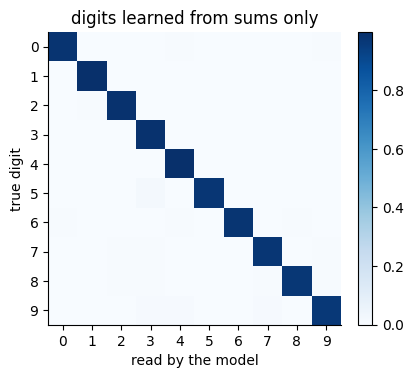

In [13]:
true_digits, predicted_digits, correct_sums = [], [], 0
for batch in DataLoader(test, batch_size=256):
    digits, totals = read(batch)
    true_digits.append(batch["digits"].flatten())
    predicted_digits.append(digits.flatten())
    correct_sums += int((totals == batch["sum"]).sum())
true_digits, predicted_digits = torch.cat(true_digits), torch.cat(predicted_digits)
print(f"digit accuracy {(true_digits == predicted_digits).float().mean():.4f}, "
      f"sum accuracy {correct_sums / len(test):.4f} on {len(test)} test sums")

confusion = torch.zeros(10, 10)
confusion.index_put_((true_digits, predicted_digits), torch.ones(len(true_digits)), accumulate=True)
plt.figure(figsize=(4.4, 3.8))
plt.imshow(confusion / confusion.sum(1, keepdim=True), cmap="Blues")
plt.colorbar(fraction=0.046)
plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel("read by the model")
plt.ylabel("true digit")
plt.title("digits learned from sums only")
plt.show()

## 8. What the model knows: inference with images and sums

The same model answers other questions. With the images alone, the digit marginals are the CNN's beliefs. **Observing the sum** as evidence propagates through the program: an image the CNN reads wrongly can be corrected, because only some digits are consistent with the sum and with the other images.

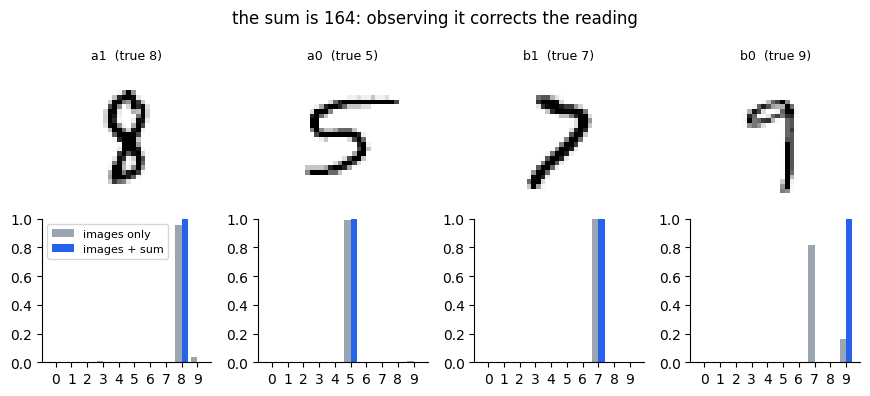

In [14]:
def digit_beliefs(batch, with_sum):
    evidence = nmln.Evidence(batch["y"], batch["observed"]) if with_sum else None
    return bp.marginals(x=batch["x"], evidence=evidence)[:, digit_index]  # [B, 2N, 10]


found = None
for batch in DataLoader(test, batch_size=256):
    before, after = digit_beliefs(batch, False), digit_beliefs(batch, True)
    wrong_before = (before.argmax(-1) != batch["digits"]).any(-1)
    right_after = (after.argmax(-1) == batch["digits"]).all(-1)
    hits = (wrong_before & right_after).nonzero().flatten()
    if len(hits):
        i = int(hits[0])
        found = {k: (v[i] if not isinstance(v, dict) else {"images": v["images"][i]}) for k, v in batch.items()}
        found["before"], found["after"] = before[i], after[i]
        break

order = list(range(N - 1, -1, -1)) + list(range(2 * N - 1, N - 1, -1))
fig, axes = plt.subplots(2, 2 * N, figsize=(2.2 * 2 * N, 4), gridspec_kw={"height_ratios": [1, 1.1]})
for col, i in enumerate(order):
    axes[0, col].imshow(found["x"]["images"][i, 0], cmap="Greys")
    axes[0, col].set_title(("a" if i < N else "b") + str(i % N) + f"  (true {int(found['digits'][i])})", fontsize=9)
    axes[0, col].axis("off")
    axes[1, col].bar(torch.arange(10) - 0.2, found["before"][i], 0.4, color=DATA, label="images only")
    axes[1, col].bar(torch.arange(10) + 0.2, found["after"][i], 0.4, color=MODEL, label="images + sum")
    axes[1, col].set_xticks(range(10))
    axes[1, col].set_ylim(0, 1)
axes[1, 0].legend(fontsize=8, loc="upper left")
plt.suptitle(f"the sum is {int(found['sum'])}: observing it corrects the reading")
plt.tight_layout()
plt.show()

**Exact samples.** On a tree, BP also draws exact samples: it samples a root variable from its marginal, then the rest of each factor given the variable above it. Given the images and the sum, the samples are complete worlds: digits and carries that add up.

In [15]:
one = {"images": found["x"]["images"].unsqueeze(0)}
given_sum = nmln.Evidence(found["y"].unsqueeze(0), found["observed"].unsqueeze(0))
for name, evidence in (("images only", None), ("images + sum", given_sum)):
    samples = bp.sample(1000, x=one, evidence=evidence)[0]
    readings = Counter(
        f"{to_number(d[:N]).item()} + {to_number(d[N:]).item()} = {to_number(t).item()}"
        for d, t in zip(samples[:, digit_index].argmax(-1), samples[:, res_index].argmax(-1))
    )
    print(f"{name:13s}", ", ".join(f"{reading} ({count / 10:.1f}%)" for reading, count in readings.most_common(3)))

images only   85 + 77 = 162 (77.6%), 85 + 79 = 164 (16.2%), 95 + 77 = 172 (2.5%)
images + sum  85 + 79 = 164 (100.0%)


## 9. Ordinary supervised learning is a special case

If the digits were observed too, the world would be complete. The program then holds with certainty, and $-\log p(y \mid x)$ is exactly the **softmax cross-entropy** of the CNN on each image, summed over the images. Learning from sums generalizes supervised learning; it does not replace it.

In [16]:
batch = default_collate([test[i] for i in range(8)])
complete = torch.stack([complete_world(ontology, d, N) for d in batch["digits"]])
nll = -bp.log_probability(nmln.Evidence.complete(complete), x=batch["x"])
cross_entropy = torch.nn.functional.cross_entropy(
    neural.logits(batch["x"]).flatten(0, 1), batch["digits"].flatten(), reduction="none"
).view(8, 2 * N).sum(1)
print("-log p(complete world | x):", nll.detach().numpy().round(4))
print("sum of cross-entropies:    ", cross_entropy.detach().numpy().round(4))

-log p(complete world | x): [0.0556 0.59   0.0021 0.0176 0.0391 1.8599 0.0332 0.0079]
sum of cross-entropies:     [0.0556 0.59   0.0022 0.0176 0.0391 1.8599 0.0332 0.0079]


## 10. Longer numbers

The same program and the same model work for any $N$; only the chain of columns gets longer. Five epochs for $N = 1, 2, 4, 15$ (`examples/mnist-addition`, recorded in `results.md`): the digit accuracy barely moves, and the sum accuracy is what independent digit errors predict, $\text{digit accuracy}^{2N}$.

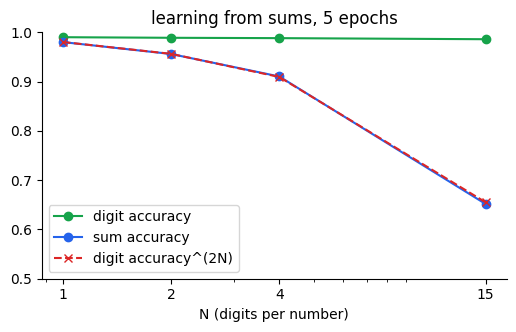

62 variables, 15 factors over 2 or more variables; a tree: BP is exact


In [17]:
rows = [line.split("|")[1:-1] for line in open("../examples/mnist-addition/results.md") if line.startswith("| ") and line[2].isdigit()]
lengths = [int(r[0]) for r in rows]
digit_acc, sum_acc = [float(r[3]) for r in rows], [float(r[4]) for r in rows]
plt.plot(lengths, digit_acc, "o-", color=NEURAL, label="digit accuracy")
plt.plot(lengths, sum_acc, "o-", color=MODEL, label="sum accuracy")
plt.plot(lengths, [d ** (2 * n) for d, n in zip(digit_acc, lengths)], "x--", color=EXACT, label="digit accuracy^(2N)")
plt.xscale("log")
plt.xticks(lengths, lengths)
plt.xlabel("N (digits per number)")
plt.ylim(0.5, 1.0)
plt.legend()
plt.title("learning from sums, 5 epochs")
plt.show()
print(nmln.BeliefPropagation(nmln.NMLN(build_language(15), [
    nmln.SymbolicPotential(build_language(15), PROGRAM[0], hard=True)])).describe().splitlines()[0])

## Summary

- Constants can carry **inputs**; the model is then conditional, $p(y \mid x)$.
- **Categorical variables** say that an image shows exactly one digit; **built-ins** hold fixed background knowledge outside the world.
- A **neural predicate** and a **symbolic program** are potentials on the same world.
- The **carry representation** makes the factor graph a tree: belief propagation is exact and linear in $N$, for log Z, marginals, MAP and samples.
- **Learning from partial observations** maximizes $p(\text{observed atoms} \mid x)$; with everything observed, it is ordinary supervised learning.

Next: notebook 3 turns to relational worlds without inputs, where potentials look at fragments of the world.

## Exercises

1. Write the program for $N = 2$ as one rule over whole numbers, with a built-in `add2(A1, A0, B1, B0, S2, S1, S0)`. What does `BeliefPropagation` say, and why?
2. Corrupt 10% of the training sums. Train once with the hard program, and once with soft rules (`hard=False`, learnable `beta`). Which reads digits better?
3. Train $N = 4$ with `nmln.MaximumLikelihood(bp).fit(loader, epochs=1)` (on a GPU if you have one) and compare its digit accuracy with $N = 2$.

<details>
<summary>Solution 1</summary>

```python
value = ontology.domains["value"]
whole = nmln.Ontology(
    list(ontology.domains.values()), list(ontology.predicates.values()),
    builtins=[nmln.Builtin("add2", [value] * 7, fn=lambda a1, a0, b1, b0, s2, s1, s0:
                           10 * a1 + a0 + 10 * b1 + b0 == 100 * s2 + 10 * s1 + s0)],
    variables=ontology.variable_declarations)
rule = ("digit(a1,A1) and digit(a0,A0) and digit(b1,B1) and digit(b0,B0) and add2(A1,A0,B1,B0,S2,S1,S0)"
        " -> res(2,S2) and res(1,S1) and res(0,S0)")
nmln.BeliefPropagation(nmln.NMLN(whole, [nmln.SymbolicPotential(whole, rule, hard=True)]))
# ValueError: a factor ... spans 7 variables with 10000000 joint configurations: one grounding reads all
# four digits and three result digits, so the factor table has 10^7 entries. The carry representation
# splits the same knowledge into small factors along a chain.
```
</details>